
# 02 概率与统计：从胜率到不确定性

> **本章要解决的问题**：一个策略胜率 60%、每笔赚 2 元亏 1 元，长期能赚钱吗？今年赚了 8 万，这个估计有多可靠？同时试了 20 个因子，至少有一个“显著”的概率有多大？

## 本章导读

这一章是整套教程的地基。后面的因子 IC、t 值、置信区间、贝叶斯更新、状态转移，都从这里长出来。

很多人学概率，一上来就是“正态分布”“大数定律”“p 值”，结果记住了一堆名词，遇到一个具体的交易账本还是不会算。这一章反过来：**先算一笔小账，再给这笔账起名字。** 十张票、二十笔交易、两个策略，这些例子会反复出现；每引入一个公式，都先把它代进这些数字里。

本章分八节：

1. 随机试验、样本空间与事件：把“涨跌”写成可计算的集合；
2. 随机变量与分布：把结果贴上一个数，才有期望和方差；
3. 期望、方差与组合：为什么两个烂策略可以拼出一个不那么烂的组合；
4. 常见分布：二项、泊松、正态、t，什么时候该用哪一个；
5. 估计与假设检验：8 万利润，是真本事还是运气；
6. 贝叶斯推断：看到新证据，怎样更新判断；
7. 马尔可夫链：把“趋势/震荡”的切换写成矩阵；
8. 统计在因子研究中的位置：IC、t 值、ICIR 到底在说什么。

### 学习目标

- 给定一组交易样本，能算均值、方差、标准误和置信区间。
- 能做一次 t 检验，并解释 p 值不是“赚钱概率”。
- 能用 bootstrap 给 IC 或收益一个经验区间。
- 能判断多重检验和样本量是否足够。
- 能用 Beta-Binomial 更新胜率，并解释先验/后验。

### 先修与读法

只需要会分数、百分数、平方和求和符号；会运行 Jupyter；不需要微积分（本章只在连续分布里用少量积分记号，理解成“面积”即可）。

每节先盖住代码，用纸笔算一遍，再运行；每节末尾有一道“停下来想一想”，答案折叠；章末有 8 道综合习题。**不要先看答案。** 看懂了不等于会算，会算不等于能在自己的数据上做对。

---


## 本章知识结构图

<svg style="max-width:100%;height:auto" xmlns="http://www.w3.org/2000/svg" width="800" height="450" viewBox="0 0 800 450" role="img" aria-label="02 概率与统计：从胜率到不确定性" font-family="Microsoft YaHei, SimHei, sans-serif">
<title>02 概率与统计：从胜率到不确定性｜知识图</title>
<desc>本章主线：点估计只是开始，标准误、置信区间和样本量才说明这个数有多可靠。</desc>
<rect x="0" y="0" width="800" height="450" fill="#FFFFFF"/>
<defs><marker id="a02" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#1B3A5C"/></marker><marker id="ao02" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#E07B39"/></marker><marker id="ag02" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#6E7B8B"/></marker></defs>
<rect x="40" y="19" width="46" height="29" fill="#E07B39" rx="8"/>
<text x="63" y="39" font-size="15" fill="#FFFFFF" text-anchor="middle" font-weight="bold">02</text>
<text x="98" y="41" font-size="22" fill="#1B3A5C" font-weight="bold">概率与统计：从胜率到不确定性</text>
<line x1="40" y1="57" x2="760" y2="57" stroke="#E6EFF7" stroke-width="2" stroke-linecap="round"/>
<line x1="40" y1="407" x2="760" y2="407" stroke="#E6EFF7" stroke-width="1.6" stroke-linecap="round"/>
<rect x="40" y="418" width="4" height="10" fill="#E07B39" rx="1"/>
<text x="52" y="428" font-size="13" fill="#6E7B8B">本章主线：点估计只是开始，标准误、置信区间和样本量才说明这个数有多可靠。</text>
<path d="M 65 300 L 550 300" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag02)"/>
<path d="M 65 300 L 65 300" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag02)"/>
<path d="M 65 300 L 65 300" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag02)"/>
<path d="M 65 300 L 65 105" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag02)"/>
<path d="M 70.4 300 L 70.4 299.2 L 74.6 299 L 78.7 298.9 L 82.9 298.7 L 87 298.4 L 91.2 298.2 L 95.4 297.9 L 99.5 297.5 L 103.7 297.1 L 107.8 296.6 L 112 296.1 L 116.2 295.5 L 120.3 294.9 L 124.5 294.1 L 128.6 293.3 L 132.8 292.4 L 137 291.4 L 141.1 290.2 L 145.3 289 L 149.4 287.6 L 153.6 286.1 L 157.8 284.4 L 161.9 282.6 L 166.1 280.6 L 170.2 278.5 L 174.4 276.2 L 178.6 273.8 L 182.7 271.2 L 186.9 268.4 L 191 265.4 L 195.2 262.3 L 199.4 259 L 203.5 255.5 L 207.7 251.9 L 211.8 248.1 L 216 244.2 L 220.2 240.2 L 224.3 236.1 L 228.5 231.9 L 232.6 227.6 L 236.8 223.2 L 241 218.8 L 245.1 214.4 L 249.3 210.1 L 253.4 205.8 L 257.6 201.5 L 261.8 197.4 L 265.9 193.3 L 270.1 189.5 L 274.2 185.8 L 278.4 182.3 L 282.6 179.1 L 286.7 176.2 L 290.9 173.5 L 295 171.1 L 299.2 169.1 L 303.4 167.4 L 307.5 166.1 L 311.7 165.1 L 315.8 164.6 L 320 164.4 L 324.2 164.6 L 328.3 165.1 L 332.5 166.1 L 336.6 167.4 L 340.8 169.1 L 345 171.1 L 349.1 173.5 L 353.3 176.2 L 357.4 179.1 L 361.6 182.3 L 365.8 185.8 L 369.9 189.5 L 374.1 193.3 L 378.2 197.4 L 382.4 201.5 L 386.6 205.8 L 390.7 210.1 L 394.9 214.4 L 399 218.8 L 403.2 223.2 L 407.4 227.6 L 411.5 231.9 L 415.7 236.1 L 419.8 240.2 L 424 244.2 L 428.2 248.1 L 432.3 251.9 L 436.5 255.5 L 440.6 259 L 444.8 262.3 L 449 265.4 L 453.1 268.4 L 457.3 271.2 L 461.4 273.8 L 465.6 276.2 L 469.8 278.5 L 473.9 280.6 L 478.1 282.6 L 482.2 284.4 L 486.4 286.1 L 490.6 287.6 L 494.7 289 L 498.9 290.2 L 503 291.4 L 507.2 292.4 L 511.4 293.3 L 515.5 294.1 L 519.7 294.9 L 523.8 295.5 L 528 296.1 L 532.2 296.6 L 536.3 297.1 L 540.5 297.5 L 544.6 297.9 L 548.8 298.2 L 553 298.4 L 557.1 298.7 L 561.3 298.9 L 565.4 299 L 569.6 299.2 L 569.6 300" fill="#E6EFF7" stroke="#E6EFF7" stroke-width="0" stroke-linecap="round" stroke-linejoin="round"/>
<path d="M 70.4 299.2 L 74.6 299 L 78.7 298.9 L 82.9 298.7 L 87 298.4 L 91.2 298.2 L 95.4 297.9 L 99.5 297.5 L 103.7 297.1 L 107.8 296.6 L 112 296.1 L 116.2 295.5 L 120.3 294.9 L 124.5 294.1 L 128.6 293.3 L 132.8 292.4 L 137 291.4 L 141.1 290.2 L 145.3 289 L 149.4 287.6 L 153.6 286.1 L 157.8 284.4 L 161.9 282.6 L 166.1 280.6 L 170.2 278.5 L 174.4 276.2 L 178.6 273.8 L 182.7 271.2 L 186.9 268.4 L 191 265.4 L 195.2 262.3 L 199.4 259 L 203.5 255.5 L 207.7 251.9 L 211.8 248.1 L 216 244.2 L 220.2 240.2 L 224.3 236.1 L 228.5 231.9 L 232.6 227.6 L 236.8 223.2 L 241 218.8 L 245.1 214.4 L 249.3 210.1 L 253.4 205.8 L 257.6 201.5 L 261.8 197.4 L 265.9 193.3 L 270.1 189.5 L 274.2 185.8 L 278.4 182.3 L 282.6 179.1 L 286.7 176.2 L 290.9 173.5 L 295 171.1 L 299.2 169.1 L 303.4 167.4 L 307.5 166.1 L 311.7 165.1 L 315.8 164.6 L 320 164.4 L 324.2 164.6 L 328.3 165.1 L 332.5 166.1 L 336.6 167.4 L 340.8 169.1 L 345 171.1 L 349.1 173.5 L 353.3 176.2 L 357.4 179.1 L 361.6 182.3 L 365.8 185.8 L 369.9 189.5 L 374.1 193.3 L 378.2 197.4 L 382.4 201.5 L 386.6 205.8 L 390.7 210.1 L 394.9 214.4 L 399 218.8 L 403.2 223.2 L 407.4 227.6 L 411.5 231.9 L 415.7 236.1 L 419.8 240.2 L 424 244.2 L 428.2 248.1 L 432.3 251.9 L 436.5 255.5 L 440.6 259 L 444.8 262.3 L 449 265.4 L 453.1 268.4 L 457.3 271.2 L 461.4 273.8 L 465.6 276.2 L 469.8 278.5 L 473.9 280.6 L 478.1 282.6 L 482.2 284.4 L 486.4 286.1 L 490.6 287.6 L 494.7 289 L 498.9 290.2 L 503 291.4 L 507.2 292.4 L 511.4 293.3 L 515.5 294.1 L 519.7 294.9 L 523.8 295.5 L 528 296.1 L 532.2 296.6 L 536.3 297.1 L 540.5 297.5 L 544.6 297.9 L 548.8 298.2 L 553 298.4 L 557.1 298.7 L 561.3 298.9 L 565.4 299 L 569.6 299.2" fill="none" stroke="#1B3A5C" stroke-width="2" stroke-linecap="round" stroke-linejoin="round"/>
<line x1="167.1" y1="300" x2="167.1" y2="200" stroke="#E07B39" stroke-width="1.3" stroke-linecap="round" stroke-dasharray="4 3"/>
<line x1="472.9" y1="300" x2="472.9" y2="200" stroke="#E07B39" stroke-width="1.3" stroke-linecap="round" stroke-dasharray="4 3"/>
<path d="M 167.1 278 L 472.9 278" fill="none" stroke="#E07B39" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ao02)" marker-start="url(#ao02)"/>
<text x="320" y="272" font-size="10" fill="#E07B39" text-anchor="middle">95% 置信区间</text>
<line x1="320" y1="300" x2="320" y2="164" stroke="#E07B39" stroke-width="1.8" stroke-linecap="round"/>
<circle cx="320" cy="164" r="4.5" fill="#E07B39"/>
<text x="320" y="154" font-size="12" fill="#1B3A5C" text-anchor="middle" font-weight="bold">μ̂</text>
<text x="163.1" y="318" font-size="8.8" fill="#6E7B8B" text-anchor="end">μ̂−1.96·SE</text>
<text x="476.9" y="318" font-size="8.8" fill="#6E7B8B">μ̂+1.96·SE</text>
<text x="90" y="340" font-size="11" fill="#6E7B8B">SE = σ̂ / √n；同样的胜率，样本越大区间越窄</text>
<text x="90" y="358" font-size="10" fill="#6E7B8B">点估计回答“是多少”，区间回答“有多确定”</text>
<text x="78" y="112" font-size="9.5" fill="#6E7B8B">密度</text>
<rect x="575" y="95" width="185" height="50" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.5" rx="14"/>
<text x="667.5" y="112.5" font-size="12.5" fill="#1B3A5C" text-anchor="middle" font-weight="bold">点估计 μ̂</text>
<text x="667.5" y="131.5" font-size="9.5" fill="#6E7B8B" text-anchor="middle">胜率 60% / 年赚 8 万</text>
<rect x="575" y="157" width="185" height="50" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.5" rx="14"/>
<text x="667.5" y="174.5" font-size="12.5" fill="#1B3A5C" text-anchor="middle" font-weight="bold">标准误 σ̂/√n</text>
<text x="667.5" y="193.5" font-size="9.5" fill="#6E7B8B" text-anchor="middle">估计本身的波动</text>
<rect x="575" y="219" width="185" height="50" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.5" rx="14"/>
<text x="667.5" y="236.5" font-size="12.5" fill="#1B3A5C" text-anchor="middle" font-weight="bold">95% 置信区间</text>
<text x="667.5" y="255.5" font-size="9.5" fill="#6E7B8B" text-anchor="middle">μ̂ ± 1.96·SE</text>
<rect x="575" y="281" width="185" height="50" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.5" rx="14"/>
<text x="667.5" y="298.5" font-size="12.5" fill="#1B3A5C" text-anchor="middle" font-weight="bold">样本量 n</text>
<text x="667.5" y="317.5" font-size="9.5" fill="#6E7B8B" text-anchor="middle">n↑ 区间变窄</text>
<path d="M 667.5 145 L 667.5 157" fill="none" stroke="#1B3A5C" stroke-width="1.7" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#a02)"/>
<path d="M 667.5 207 L 667.5 219" fill="none" stroke="#1B3A5C" stroke-width="1.7" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#a02)"/>
<path d="M 575 289 Q 548 240 575 165" fill="none" stroke="#6E7B8B" stroke-width="1.2" stroke-linecap="round" stroke-linejoin="round" stroke-dasharray="4 3" marker-end="url(#ag02)"/>
</svg>

> **图**：本章主线：点估计只是开始，标准误、置信区间和样本量才说明这个数有多可靠。



### 环境准备

下面的代码设置中文字体，避免图中汉字变成方框。如果你在别的电脑上运行，把字体换成自己系统里有的中文字体即可（比如 `SimHei`、`Microsoft YaHei`、`PingFang SC`）。



In [1]:

import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
print("matplotlib 中文字体已设置")


matplotlib 中文字体已设置



## 在量化研究中的位置

- **谁用**：因子研究员、风控、策略评估。
- **输入**：收益/交易/IC 样本。
- **输出**：均值与区间、p 值、后验、样本量估计。
- **在流程的哪一步**：验证与统计推断：判断“这点收益是不是运气”。
- **失败模式**：把 p 值当胜率、忽略多重检验、把不独立样本当独立。
- **最小工作流**：描述统计 → 置信区间 → 假设检验 → 多重检验校正 → 写进报告。

---
## 1. 随机试验、样本空间与事件

### 1.1 从十张票开始

桌上放十张同样大小的纸条：六张写“涨”，四张写“跌”。闭眼均匀抽一张，揭开前不知道会抽中哪一张。

把这件事拆成四个词：

- **随机试验**：抽一次票。它有两个以上可能结果，事先不知道哪一个会发生；
- **样本空间** $\Omega$：所有可能结果的集合，这里是 $\{\text{涨},\text{跌}\}$；
- **事件** $A$：你关心的一组结果，比如“抽到涨”；
- **概率** $P(A)$：在抽取规则下，$A$ 发生的可能性大小。

十张票等可能，六张满足条件，所以

$$P(\text{涨})=\frac{6}{10}=0.6.$$

这个 0.6 不是“市场明天上涨的概率”，而是“在一个明确的抽取规则下，涨票占的比例”。真实市场不会发给你一袋票；历史频率只是估计概率的材料。**概率模型是对数据的描述，不是对未来的保证。** 这句话在后面的因子研究里会反复出现：样本里的 60% 胜率，不等于未来的 60%。

### 1.2 三条公理

概率不是随口说的数，它要满足三条规则：

> **定义 1.1（概率公理）**
> 1. **非负性**：对任意事件 $A$，$P(A)\ge 0$；
> 2. **规范性**：$P(\Omega)=1$；
> 3. **可列可加性**：若 $A_1,A_2,\dots$ 两两不相交，则
>    $$P\left(\bigcup_i A_i\right)=\sum_i P(A_i).$$

由此可以推出几条常用规则：

| 规则 | 公式 | 人话 |
|---|---|---|
| 补事件 | $P(A^c)=1-P(A)$ | 不发生的概率等于 1 减去发生 |
| 加法 | $P(A\cup B)=P(A)+P(B)-P(A\cap B)$ | 两个事件合起来，要减掉重复算的部分 |
| 差集 | $P(A\cap B^c)=P(A)-P(A\cap B)$ | 只在 A 不在 B |

十张票里，“抽到涨或抽到跌”是必然事件，概率为 1；“抽到涨且抽到跌”不可能，概率为 0。这些看起来是废话，但很多人算组合概率时，恰恰忘了减掉交集。

### 1.3 条件概率：知道 B 之后，A 的概率

假设你提前知道“抽到的票来自放量日”，这时十张票的构成变了，概率要重新数。条件概率的定义是

$$P(A\mid B)=\frac{P(A\cap B)}{P(B)},\qquad P(B)>0.$$

分母是 $P(B)$，不是 1。**条件概率就是把样本空间缩小到 B 里面，再数 A 占多少。**

举一个交易版的例子。100 个交易日：

- 60 天上涨，40 天下跌；
- 50 天放量，其中 40 天上涨、10 天下跌。

于是：

$$P(\text{涨})=0.6,\quad P(\text{放量})=0.5,\quad P(\text{涨}\cap\text{放量})=0.4.$$

看到放量之后，上涨的条件概率是

$$P(\text{涨}\mid\text{放量})=\frac{0.4}{0.5}=0.8.$$

反过来，上涨的日子里放量的比例是

$$P(\text{放量}\mid\text{涨})=\frac{0.4}{0.6}\approx 0.667.$$

这两个数不一样。**$P(\text{涨}\mid\text{放量})$ 回答“看到放量后，上涨的可能性多大”；$P(\text{放量}\mid\text{涨})$ 回答“上涨的日子里，有多少是放量的”。** 交易信号关心的是前者，不是后者。

### 1.4 独立：知道 B 不改变 A

如果

$$P(A\cap B)=P(A)P(B),$$

称 $A$ 与 $B$ 独立。等价地，若 $P(B)>0$，则 $P(A\mid B)=P(A)$。

上面的例子里，$P(\text{涨})P(\text{放量})=0.6\times0.5=0.3$，而 $P(\text{涨}\cap\text{放量})=0.4$，所以不独立——放量的日子里上涨更多。

独立是模型假设，不是数据里自动成立的事实。很多策略回测默认“每天独立”，但同一天的多个品种、相邻的交易日，往往并不独立。后面讲标准误和 t 值时，这个假设会直接决定你的结论可不可信。

### 1.5 代码：把 100 天模拟出来

下面用 20 万次模拟，验证上面的四个概率。`up` 是布尔数组，`high` 是另一个布尔数组；`up[high].mean()` 就是“放量的日子里上涨的比例”。



In [2]:

import numpy as np

rng = np.random.default_rng(2026)
n = 200_000

# 先抽涨跌，再按 P(放量|涨)=2/3、P(放量|跌)=1/4 抽放量
up = rng.random(n) < 0.6
high = np.where(up, rng.random(n) < 40 / 60, rng.random(n) < 10 / 40)

print("P(涨)        =", round(up.mean(), 4))
print("P(放量)      =", round(high.mean(), 4))
print("P(涨且放量)  =", round((up & high).mean(), 4))
print("P(涨|放量)   =", round(up[high].mean(), 4))
print("P(放量|涨)   =", round(high[up].mean(), 4))


P(涨)        = 0.6024
P(放量)      = 0.5017
P(涨且放量)  = 0.402
P(涨|放量)   = 0.8013
P(放量|涨)   = 0.6673



**读数与应用**：模拟值会在 0.6、0.5、0.4、0.8、0.667 附近小幅波动，这是抽样误差，不是代码错了。真实数据里，你只有一次抽样，所以每个概率都带着不确定性；第 5 节会量化这个不确定性。

**常见错误**：

1. 把 $P(\text{涨}\mid\text{放量})$ 和 $P(\text{放量}\mid\text{涨})$ 当成一回事。交易信号要的是前者。
2. 看到两个事件同时出现，就说“有因果关系”。条件概率只描述关联，不说明谁导致谁。
3. 忘了分母。算“放量后上涨的概率”时，分母是放量天数，不是全部天数。

**停下来想一想**：如果 $P(\text{涨}\mid\text{放量})=0.8$，能不能直接说“放量是上涨的原因”？

<details><summary>对照你的思路</summary>

不能。可能是放量导致上涨，也可能是上涨吸引了更多交易所以放量，还可能是第三个因素（比如重大消息）同时导致两者。条件概率只告诉你“在放量的条件下，上涨更常见”，要谈因果，需要额外的识别策略（自然实验、工具变量、时间先后等）。在量化研究里，先分清“预测”和“因果”，能避免很多过度解释。

</details>

### 1.6 全概率公式：把不同情形加权

如果事件 $B_1,B_2$ 把样本空间分成两块（互斥且穷尽），那么

$$P(A)=P(A\mid B_1)P(B_1)+P(A\mid B_2)P(B_2).$$

这就是全概率公式：**先分情形，再按情形出现的概率加权。**

例子：60% 的日子是趋势市，40% 是震荡市；趋势市里 70% 出现“延续”，震荡市里 20% 也出现。那么

$$P(\text{延续})=0.6\times0.7+0.4\times0.2=0.5.$$

在这个例子里，延续出现时是趋势市的概率是

$$P(\text{趋势}\mid\text{延续})=\frac{0.6\times0.7}{0.5}=0.84.$$

这就是贝叶斯公式的雏形：分子是“趋势且延续”，分母是“所有可能延续的情形”。第 6 节会把它写成一般的先验—似然—后验。

---



## 2. 随机变量与分布

### 2.1 给每个结果贴一个数

上一节的“涨/跌”是文字，没法直接做加减乘除。我们给每个结果贴一个数：

- 涨：$X=+2$ 元；
- 跌：$X=-1$ 元。

这样 $X$ 就是一个**随机变量**：它是从样本空间到实数的一个规则。名字听起来抽象，其实只是“每种结果对应多少钱”。

> **定义 2.1（离散随机变量与分布）** 若 $X$ 只能取有限个或可列个值 $x_1,x_2,\dots$，称 $X$ 为离散随机变量。它的**概率质量函数**（PMF）是
> $$p(x_i)=P(X=x_i),$$
> 满足 $p(x_i)\ge 0$ 且 $\sum_i p(x_i)=1$。

把十张票的分布写成表：

| 结果 | 票数 | $X$ | $p(x)$ |
|---|---:|---:|---:|
| 涨 | 6 | $+2$ | 0.6 |
| 跌 | 4 | $-1$ | 0.4 |

这张表就是全部信息。**分布是一张“结果—概率”的对照表**；有了它，期望、方差、尾部概率都可以算。

### 2.2 期望：长期平均能拿多少

期望是“按概率加权的平均”：

$$E[X]=\sum_i x_i\,p(x_i).$$

十张票的例子：

$$E[X]=2\times0.6+(-1)\times0.4=1.2-0.4=0.8\text{ 元}.$$

如果每张票恰好出现一次，总盈亏是 $6\times2-4\times1=8$ 元，除以 10 张，也是 0.8 元。两种算法一致，因为概率就是出现比例。

期望有几个常用性质，后面会反复用：

| 性质 | 公式 | 注意 |
|---|---|---|
| 线性 | $E[aX+b]=aE[X]+b$ | 对任何随机变量都成立，不要求独立 |
| 相加 | $E[X+Y]=E[X]+E[Y]$ | 同样不要求独立 |
| 乘积 | 若 $X,Y$ 独立，$E[XY]=E[X]E[Y]$ | 不独立时一般不成立 |

“期望线性”是概率里最容易被低估的性质：它不需要独立，所以组合的期望可以直接相加；但组合的**方差**不能直接相加，因为还有协方差。

### 2.3 方差：平均一样，风险一样吗

甲、乙两个游戏，平均都付 0 元：

- 甲：永远付 0；
- 乙：各一半概率付 $+3$ 或 $-3$。

均值一样，但乙的结果更分散。为了量化“分散”，先算每个结果与均值的差（偏差），平方后按概率平均：

$$\operatorname{Var}(X)=E\left[(X-E[X])^2\right].$$

**公式拆解**
- **符号**：$X$ 单笔盈亏（元），$E[X]$ 均值；$X-E[X]$ 是偏差（元），平方后单位变元$^2$。
- **结构**：偏差平方的加权平均；也可用 $E[X^2]-(E[X])^2$，开根号回到元。
- **代入**：乙游戏 $+3/-3$ 各半 → 均值 0，方差 $0.5\times9+0.5\times9=9$，SD 3 元。
- **边界**：方差恒 $\ge0$，为 0 即恒定；厚尾（$t$ 自由度 $\le2$）时方差不存在。
- **用途**：算组合方差/SD/Sharpe；不是最大亏损，方差也不能直接相加。

展开平方，得到另一个常用公式：

$$\operatorname{Var}(X)=E[X^2]-(E[X])^2.$$

标准差是方差的平方根，单位回到“元”：

$$\operatorname{SD}(X)=\sqrt{\operatorname{Var}(X)}.$$

十张票的例子，均值 0.8：

$$\operatorname{Var}(X)=0.6(2-0.8)^2+0.4(-1-0.8)^2=0.6\times1.44+0.4\times3.24=2.16.$$

标准差是 $\sqrt{2.16}\approx1.47$ 元。

方差的性质：

| 性质 | 公式 |
|---|---|
| 平移 | $\operatorname{Var}(X+b)=\operatorname{Var}(X)$ |
| 缩放 | $\operatorname{Var}(aX)=a^2\operatorname{Var}(X)$ |
| 和的方差 | $\operatorname{Var}(X+Y)=\operatorname{Var}(X)+\operatorname{Var}(Y)+2\operatorname{Cov}(X,Y)$ |

注意缩放是 $a^2$，不是 $a$。杠杆放大两倍，波动放大两倍，方差放大四倍。

### 2.4 连续分布：密度不是概率

当结果可以是任意小数（比如收益率），不能再逐张列票。把数轴切成很多小区间，用**面积**表示落入区间的概率。区间越细，直方图越像一条曲线；曲线的高度叫**概率密度函数**（PDF）$f(x)$，面积才是概率：

$$P(a<X<b)=\int_a^b f(x)\,dx.$$

**累积分布函数**（CDF）是

$$F(x)=P(X\le x)=\int_{-\infty}^x f(t)\,dt.$$

$F$ 单调不减，从 0 到 1；$f$ 是 $F$ 的导数（在光滑处）。

一个常见误解：密度可以大于 1。比如均匀分布在 $[0,0.5]$ 上，密度是 2；但任何区间的概率仍然不超过 1。**密度是“单位长度的概率”，不是概率本身。**

另一个结论：连续分布下，$P(X=x)=0$。单个点没有宽度，面积为零。真实报价有最小跳动，所以离散模型里单点可以有正概率；这是模型选择的问题，不是数学矛盾。

### 2.5 代码：PMF 与 CDF



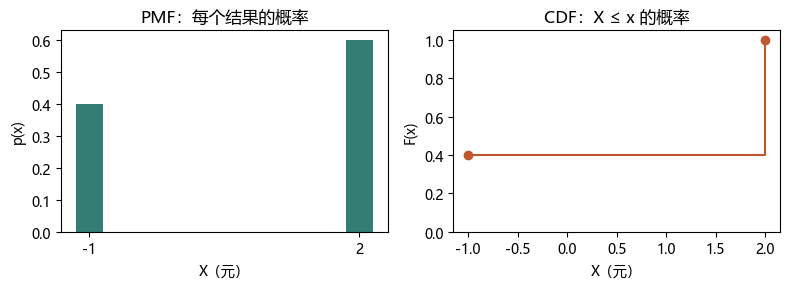

In [3]:

import numpy as np
import matplotlib.pyplot as plt

x = np.array([-1.0, 2.0])
p = np.array([0.4, 0.6])

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].bar(x, p, width=0.3, color="#337d75")
axes[0].set(title="PMF：每个结果的概率", xlabel="X（元）", ylabel="p(x)")
axes[0].set_xticks(x)

cdf = np.cumsum(p)
axes[1].step(x, cdf, where="post", color="#be572e")
axes[1].scatter(x, cdf, color="#be572e")
axes[1].set(title="CDF：X ≤ x 的概率", xlabel="X（元）", ylabel="F(x)", ylim=(0, 1.05))

plt.tight_layout()
plt.show()



**读数与应用**：左图是“每个结果多少钱、概率多大”；右图是“累计到某个值为止的概率”。CDF 的跳跃高度就是对应结果的概率。实盘里，CDF 更常用：你想知道“亏损超过 2 元的概率”，就是 $1-F(-2)$。

**常见错误**：

1. 把密度当成概率。$f(0)=0.4$ 不表示“收益恰好为 0 的概率是 0.4”。
2. 忘了方差是平方单位。方差 2.16 的单位是“元²”，标准差 1.47 才是“元”。
3. 把“期望”当成“下一次会拿到的钱”。期望是长期重复的平均，不是单次结果。

**停下来想一想**：如果一笔固定费用 1 元，十张票的净期望是多少？方差变了吗？

<details><summary>对照你的思路</summary>

净收益 $Y=X-1$，所以 $E[Y]=E[X]-1=0.8-1=-0.2$ 元。方差不变，因为平移不改变分散程度：$\operatorname{Var}(Y)=\operatorname{Var}(X)=2.16$。这就是“胜率 60% 仍可能亏钱”的最简单例子：方向猜对的比例不低，但扣除费用后，平均每笔是负的。

</details>

### 2.6 两个公式的推导

**方差展开**：

$$
\operatorname{Var}(X)=E[(X-\mu)^2]
=E[X^2-2\mu X+\mu^2]
=E[X^2]-2\mu E[X]+\mu^2
=E[X^2]-\mu^2.
$$

最后一步用了 $\mu=E[X]$。十张票：$E[X^2]=0.6\times4+0.4\times1=2.8$，$\mu^2=0.64$，所以方差 $2.16$，和逐项算一致。

**缩放**：

$$
\operatorname{Var}(aX+b)=E[(aX+b-a\mu-b)^2]
=E[a^2(X-\mu)^2]
=a^2\operatorname{Var}(X).
$$

平移 $b$ 不影响偏差；缩放 $a$ 把偏差放大 $a$ 倍，平方后是 $a^2$。

这两个推导都很短，但它们是后面组合方差、杠杆、标准误的基础。**不要背结论，跟着等号走一遍。**

---



## 3. 期望、方差与组合

### 3.1 两个随机变量：协方差与相关系数

只看单个策略不够。组合里有两个策略 $X,Y$，它们可能同涨同跌，也可能一个涨一个跌。协方差衡量“一起偏离各自均值的程度”：

$$\operatorname{Cov}(X,Y)=E\left[(X-E[X])(Y-E[Y])\right]=E[XY]-E[X]E[Y].$$

协方差的正负号比大小更有用：

- 正：同向偏离；
- 负：反向偏离；
- 零：线性不相关（不一定独立）。

协方差受单位影响，不方便比较。除以两个标准差，得到相关系数：

$$\rho_{XY}=\frac{\operatorname{Cov}(X,Y)}{\operatorname{SD}(X)\operatorname{SD}(Y)},\qquad -1\le\rho\le1.$$

$\rho=1$ 完全同向，$\rho=-1$ 完全反向，$\rho=0$ 线性无关。

### 3.2 组合的方差

设两个策略的权重为 $w$ 和 $1-w$，组合收益是

$$R=wX+(1-w)Y.$$

方差是

$$\operatorname{Var}(R)=w^2\operatorname{Var}(X)+(1-w)^2\operatorname{Var}(Y)+2w(1-w)\operatorname{Cov}(X,Y).$$

最后一项是“交叉项”。如果两个策略独立，协方差为零，交叉项消失；如果负相关，交叉项为负，组合方差会比两个方差的加权平均更小。这就是分散化。

举个数字例子。$\operatorname{Var}(X)=4$，$\operatorname{Var}(Y)=9$，$\rho=-0.2$：

$$\operatorname{Cov}(X,Y)=-0.2\times2\times3=-1.2.$$

取 $w=0.5$：

$$\operatorname{Var}(R)=0.25\times4+0.25\times9+2\times0.25\times(-1.2)=1+2.25-0.6=2.65.$$

组合标准差 $\sqrt{2.65}\approx1.63$，而两个标准差的简单平均是 $(2+3)/2=2.5$。**负相关让组合波动从 2.5 降到 1.63**，代价是你放弃了一部分高收益策略的权重。

### 3.3 样本与总体：为什么除以 $n-1$

上面的方差是“总体方差”，你已经知道真实的均值。现实中你只有样本，均值也要估计。这时用样本方差：

$$s^2=\frac{1}{n-1}\sum_{i=1}^n (x_i-\bar x)^2.$$

分母是 $n-1$ 而不是 $n$，因为用样本均值代替真实均值，会消耗一个自由度：偏差之和被强制为零，只剩 $n-1$ 个独立方向。除以 $n-1$ 使 $s^2$ 无偏；除以 $n$ 会系统性低估。

样本均值的标准差叫**标准误**：

$$\operatorname{SE}(\bar x)=\frac{s}{\sqrt n}.$$

$n$ 越大，标准误越小，但按 $\sqrt n$ 缩小：样本从 100 增到 400，标准误只减半。**标准误衡量的是“均值估计有多稳”，不是“单笔交易有多安全”。** 这两件事经常被混为一谈。

### 3.4 代码：组合方差曲线



In [4]:

import numpy as np

var_x, var_y, rho = 4.0, 9.0, -0.2
cov = rho * np.sqrt(var_x) * np.sqrt(var_y)

for w in [0.0, 0.25, 0.5, 0.75, 1.0]:
    var = w * w * var_x + (1 - w) ** 2 * var_y + 2 * w * (1 - w) * cov
    print(f"w={w:.2f}  组合方差={var:.3f}  组合波动={np.sqrt(var):.3f}")

print("协方差 =", cov)


w=0.00  组合方差=9.000  组合波动=3.000
w=0.25  组合方差=4.862  组合波动=2.205
w=0.50  组合方差=2.650  组合波动=1.628
w=0.75  组合方差=2.362  组合波动=1.537
w=1.00  组合方差=4.000  组合波动=2.000
协方差 = -1.2000000000000002



**读数与应用**：权重从 0 到 1 扫一遍，组合波动先降后升，最低点通常不在端点。真实组合优化就是在这个曲线上找“给定收益下波动最小”的点；第 9 章会用二次规划正式求解。

**常见错误**：

1. 把“两个策略都好”直接等于“组合更好”。如果它们高度正相关，组合并不能分散风险。
2. 用价格的相关系数代替收益的相关系数。价格同涨同跌可能只是共同趋势，收益的相关性才是组合风险的关键。
3. 忘了 $w$ 和 $1-w$ 的约束。实盘还有保证金、手数、涨跌停，理论权重不一定能落地。

**停下来想一想**：负相关一定能降低组合风险吗？

<details><summary>对照你的思路</summary>

不一定。若权重选得极端（比如 90% 押在低波动策略上），组合风险可能仍高于最优权重；若两个策略的负相关来自同一个风险因子（比如一个做多波动、一个做空波动），在极端行情下相关性会突然变正，分散化失效。负相关是“平均意义上”的缓冲，不是保险。

</details>

### 3.5 相关系数的四个坑

相关系数只衡量**线性**关系，而且对异常值敏感。四个常见坑：

1. **非线性依赖**：$X$ 在 $[-1,1]$ 上均匀分布，$Y=X^2$。$X$ 与 $Y$ 明显依赖，但 $\rho=0$。相关系数为零，不等于独立。
2. **异常值**：一个极端点可以把 $\rho$ 从 0.1 拉到 0.8，也可以从 0.8 拉到 0.1。算相关前先画散点图，或至少做缩尾。
3. **共同趋势**：两条都随时间上涨的价格序列，即使毫无关系，相关系数也可能很高。价格水平的相关，常常只是“都涨了”；收益的相关才是组合风险需要的。
4. **尾部相关**：平时 $\rho=0.2$，危机时可能变成 0.8。用全样本算一个平均数，会低估极端行情下的组合风险。

一句话：**相关系数是摘要，不是事实。** 用它之前，先看散点、看时间、看尾部。

---



## 4. 常见分布：什么时候该用哪一个

### 4.1 一张表记住五个分布

| 分布 | 用来描述什么 | 参数 | 均值 | 方差 |
|---|---|---|---:|---:|
| 伯努利 $Bernoulli(p)$ | 一次成败（涨/跌、对/错） | $p$ | $p$ | $p(1-p)$ |
| 二项 $Binomial(n,p)$ | $n$ 次独立成败中成功几次 | $n,p$ | $np$ | $np(1-p)$ |
| 泊松 $Poisson(\lambda)$ | 单位时间内事件到达几次 | $\lambda$ | $\lambda$ | $\lambda$ |
| 均匀 $Uniform(a,b)$ | 区间内等可能 | $a,b$ | $(a+b)/2$ | $(b-a)^2/12$ |
| 正态 $N(\mu,\sigma^2)$ | 大量独立小冲击的叠加 | $\mu,\sigma$ | $\mu$ | $\sigma^2$ |
| t 分布 $t(\nu)$ | 小样本、均值未知、尾部更厚 | $\nu$ | 0（$\nu>1$） | $\nu/(\nu-2)$（$\nu>2$） |

选分布不是看哪个“高级”，而是看数据的生成机制：

- 一次交易对/错：伯努利；
- 20 次交易对几次：二项；
- 一分钟来几笔订单：泊松；
- 日收益率：常用正态做基准，但要知道它有厚尾；
- 小样本的均值检验：t 分布。

### 4.2 正态分布：基准，不是真理

正态分布由均值和标准差决定，记 $X\sim N(\mu,\sigma^2)$。标准化后 $Z=(X-\mu)/\sigma\sim N(0,1)$，所以任何正态概率都能查标准正态表：

$$P(a<X<b)=\Phi\left(\frac{b-\mu}{\sigma}\right)-\Phi\left(\frac{a-\mu}{\sigma}\right).$$

经验法则：约 68% 落在 $\mu\pm\sigma$，95% 落在 $\mu\pm2\sigma$，99.7% 落在 $\mu\pm3\sigma$。

正态分布重要，是因为**中心极限定理**：大量独立同分布的随机变量相加，其均值近似正态，不管原始分布是什么。这解释了为什么“样本均值”的分布常常接近正态；但它不保证“原始收益”是正态。真实收益的尾部通常比正态厚，极端事件比 99.7% 更常见。

### 4.3 t 分布：小样本与厚尾

t 分布比正态多一个参数：自由度 $\nu$。$\nu$ 越小，尾部越厚；$\nu\to\infty$ 时趋近标准正态。

t 分布有两个常见用途：

1. **小样本均值检验**：用样本标准差代替未知总体标准差，统计量服从 $t_{n-1}$；
2. **给厚尾收益建模**：把 t 缩放成单位方差，比较它和正态在尾部的差异。

注意：t 分布的自由度不是“样本量”本身，而是由具体问题决定。单样本均值检验是 $n-1$；回归里是 $n-k$。不要背成“t 就是小样本”。

### 4.4 泊松分布：订单为什么成簇

泊松分布描述“单位时间内事件到达的次数”：

$$P(N=k)=e^{-\lambda}\frac{\lambda^k}{k!},\qquad k=0,1,2,\dots$$

均值与方差都等于 $\lambda$。若一分钟平均来 2 单，零单概率是 $e^{-2}\approx0.135$，至少一单是 $1-0.135=0.865$。

泊松的关键假设是：事件独立、强度恒定。真实订单流往往不满足——一笔大单会引来跟风，强度会聚集。这时用泊松会低估“连续多笔”的概率；第 8 章的 Hawkes 过程就是放松这个假设的模型。

### 4.5 大数定律与中心极限定理

**大数定律**：样本均值随 $n$ 增大，趋近总体均值。

$$\bar X_n\to\mu.$$

**中心极限定理**：在独立同分布、方差有限的条件下，

$$\frac{\bar X_n-\mu}{\sigma/\sqrt n}\xrightarrow{d}N(0,1).$$

**公式拆解**
- **符号**：$\bar X_n$ 前 $n$ 笔均值，$\mu$ 总体均值，$\sigma/\sqrt n$ 是标准误。
- **结构**：分子=均值偏离，分母=标准误；比值=偏离几个标准误，$n$ 大时趋于 $N(0,1)$。
- **代入**：$\sigma=2.16$、$n=100$ → $SE=0.216$；若 $\bar X=0.8$，$z=3.70$。
- **边界**：厚尾（方差无限）或有自相关时 $\sigma/\sqrt n$ 失效，$z$ 虚高。
- **用途**：SE、置信区间、IC 的 $t$ 值都靠它；不能反推“收益是正态的”。

两句话的区别：

- 大数定律说“均值会稳”；
- 中心极限定理说“均值围绕真实值怎么波动”，并给出标准误 $\sigma/\sqrt n$。

这解释了为什么“样本越多，估计越准”，也解释了为什么“单笔交易的风险”不会因为样本变多而下降。样本变多，你更了解这个策略的平均值，但下一笔仍然可能亏。

### 4.6 代码：分布形状与中心极限定理



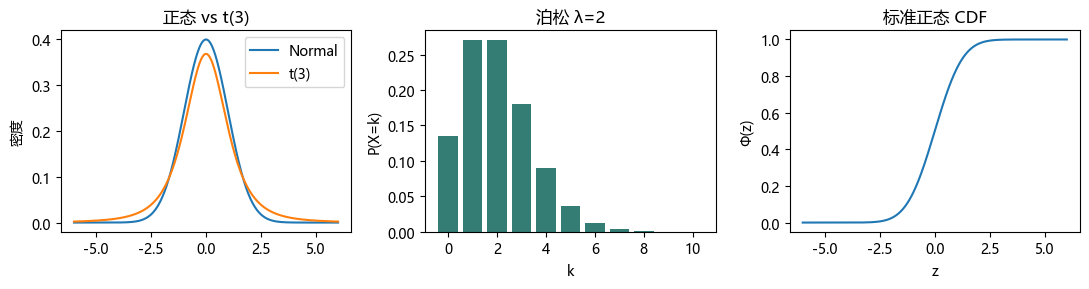

In [5]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, t, poisson

fig, axes = plt.subplots(1, 3, figsize=(11, 3))

xs = np.linspace(-6, 6, 500)
axes[0].plot(xs, norm.pdf(xs), label="Normal")
axes[0].plot(xs, t.pdf(xs, 3), label="t(3)")
axes[0].set(title="正态 vs t(3)", ylabel="密度")
axes[0].legend()

ks = np.arange(0, 11)
axes[1].bar(ks, poisson.pmf(ks, 2), color="#337d75")
axes[1].set(title="泊松 λ=2", xlabel="k", ylabel="P(X=k)")

axes[2].plot(xs, norm.cdf(xs))
axes[2].set(title="标准正态 CDF", xlabel="z", ylabel="Φ(z)")

plt.tight_layout()
plt.show()


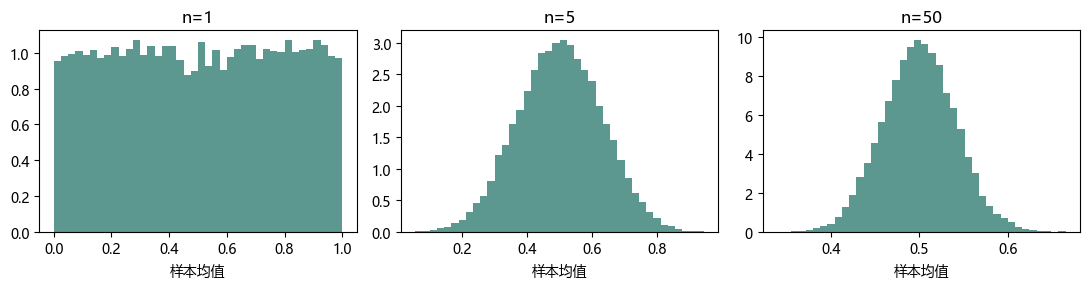

In [6]:

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)
fig, axes = plt.subplots(1, 3, figsize=(11, 3))

for ax, n in zip(axes, [1, 5, 50]):
    means = rng.uniform(0, 1, size=(20_000, n)).mean(axis=1)
    ax.hist(means, bins=40, density=True, color="#337d75", alpha=0.8)
    ax.set(title=f"n={n}", xlabel="样本均值")

plt.tight_layout()
plt.show()



**读数与应用**：左图里 t(3) 的尾部明显比正态厚；中间的泊松分布右偏；右图是标准正态 CDF。第二组图里，$n=1$ 时样本均值就是原始均匀分布，$n=50$ 时已经接近钟形——这就是中心极限定理的视觉效果。

**常见错误**：

1. “收益率服从正态分布。” 日收益的峰度通常高于正态，极端值更多；正态是好用的基准，不是事实。
2. “t 检验就是 t 分布。” t 检验的统计量在零假设下服从 t 分布；t 分布本身也可以用来给厚尾建模，两者不是一回事。
3. “样本越多，下一笔越安全。” 样本越多，均值的标准误越小；单笔方差不变。

**停下来想一想**：为什么样本均值会越来越集中，而单笔收益不会？

<details><summary>对照你的思路</summary>

样本均值是 $n$ 个独立（或近似独立）观测的平均，正负冲击会互相抵消，方差是 $\sigma^2/n$，所以随 $n$ 缩小。单笔收益只有一个观测，方差仍是 $\sigma^2$。这就是“估计的确定性”和“结果的风险”是两件事的原因。仓位管理关心后者，研究结论关心前者。

</details>

### 4.7 选分布的决策树

拿到一列数据，先问四个问题：

1. **是计数吗？** 是 -> 伯努利（一次成败）/ 二项（固定次数中的成功数）/ 泊松（单位时间到达数）。
2. **是连续金额吗？** 是 -> 先看直方图：对称钟形用正态；尾部厚、样本小用 t；区间内等可能用均匀。
3. **是等待时间吗？** 是 -> 指数分布（泊松过程的间隔时间）。
4. **只关心极端值吗？** 是 -> 广义帕累托分布（极值理论），或者直接用历史分位数。

如果拿不准，先用**经验分布**：不假设形状，直接看分位数、做 bootstrap。分布是工具，不是信仰；选错了，后面所有标准误和 p 值都会错。

### 4.8 泊松分布从哪里来

把一分钟切成 $n$ 个很小的时间格，每格最多来一单，来的概率是 $\lambda/n$，各格独立。这一分钟来 $k$ 单的概率是二项分布：

$$P(N=k)=\binom{n}{k}\left(\frac{\lambda}{n}\right)^k\left(1-\frac{\lambda}{n}\right)^{n-k}.$$

让 $n\to\infty$：

$$\binom{n}{k}\frac{\lambda^k}{n^k}\to\frac{\lambda^k}{k!},\qquad \left(1-\frac{\lambda}{n}\right)^{n-k}\to e^{-\lambda}.$$

所以

$$P(N=k)\to e^{-\lambda}\frac{\lambda^k}{k!}.$$

这就是泊松分布。它假设“每格独立、强度恒定”；如果一笔大单会引来跟风，独立性被破坏，泊松就会低估连续多笔的概率。第 8 章的 Hawkes 过程，就是放松“强度恒定”的模型。

---



## 5. 估计与假设检验：8 万利润，是真本事还是运气

### 5.1 估计量：你算出来的数，本身也是随机变量

总体参数（比如真实平均每笔盈亏 $\mu$）通常不知道；你用样本算一个估计量 $\hat\mu$。换一批样本，$\hat\mu$ 会变，所以**估计量也是随机变量**。

评价一个估计量，看三件事：

| 指标 | 定义 | 人话 |
|---|---|---|
| 偏差 | $\operatorname{Bias}(\hat\theta)=E[\hat\theta]-\theta$ | 平均而言，离真值有多远 |
| 方差 | $\operatorname{Var}(\hat\theta)$ | 换样本时，估计值抖得多厉害 |
| 均方误差 | $\operatorname{MSE}=\operatorname{Bias}^2+\operatorname{Var}$ | 综合误差 |

样本均值 $\bar x$ 是 $\mu$ 的无偏估计；样本方差 $s^2$（除以 $n-1$）是 $\sigma^2$ 的无偏估计。无偏不等于“每次都对”，只表示“重复抽样时平均对准”。

标准误是估计量的标准差：

$$\operatorname{SE}(\bar x)=\frac{\sigma}{\sqrt n}\approx\frac{s}{\sqrt n}.$$

它回答的是“如果我再抽一批样本，均值会抖多少”，不是“下一笔交易会不会亏”。

### 5.2 置信区间：一个会动的网

95% 置信区间常写成

$$\bar x\pm t_{1-\alpha/2,\,n-1}\frac{s}{\sqrt n}.$$

正确解释是：**如果反复独立取样，每次都按同一规则造一个区间，大约 95% 的区间会盖住固定的真值。** 不是“这个区间有 95% 的概率包含真值”——真值是固定的，区间是随机的；一次算完的区间，要么盖住，要么没盖住。

这个区别听起来学究，但很重要：它意味着置信区间衡量的是“方法的长期覆盖率”，不是“这次结论的可信度”。贝叶斯可信区间才直接对参数给概率，第 6 节会讲。

### 5.3 假设检验：先假设一个世界，再看数据有多反常

假设检验的流程：

1. 写零假设 $H_0$（通常是“没有效应”“均值等于 0”）；
2. 写备择假设 $H_1$（你真正想证明的方向）；
3. 选一个检验统计量 $T$；
4. 算 $p$ 值：在 $H_0$ 成立时，得到当前这么大或更极端结果的概率；
5. 若 $p<\alpha$，拒绝 $H_0$。

单样本 t 检验：

$$t=\frac{\bar x-\mu_0}{s/\sqrt n},\qquad t\sim t_{n-1}\text{（在 }H_0\text{ 下）}.$$

**公式拆解**
- **符号**：$\bar x$ 均值（元），$\mu_0$ 零假设均值，$s$ 样本标准差，$n$ 样本量；$df=n-1$。
- **结构**：信号/噪声；分子是效应，分母是标准误，也可写成 $\frac{\bar x-\mu_0}{s}\sqrt n$。
- **代入**：20 笔，$\bar x=0.8$、$s=2.16$ → SE $=0.483$，$t=1.66<1.729$，不显著。
- **边界**：$s=0$ 或 $n=1$ 时无定义；多重检验让“显著”变便宜。
- **用途**：均值与 IC 的显著性；不是赚钱概率，不显著也不等于无效。

两类错误：

| | $H_0$ 为真 | $H_0$ 为假 |
|---|---|---|
| 拒绝 $H_0$ | 第一类错误（$\alpha$） | 正确（power $=1-\beta$） |
| 不拒绝 $H_0$ | 正确 | 第二类错误（$\beta$） |

$\alpha$ 是你愿意接受的“冤枉好人”的概率；power 是“抓住坏人”的概率。样本越小、效应越弱，power 越低；“不显著”很可能只是“样本不够”，不是“没有效应”。

### 5.4 手算：20 笔交易的均值检验

假设 20 笔交易，平均每笔 $\bar x=0.8$ 元，样本标准差 $s=2.16$ 元。检验“真实均值是否大于 0”：

$$\operatorname{SE}=\frac{2.16}{\sqrt{20}}\approx0.483,$$

$$t=\frac{0.8}{0.483}\approx1.66,\qquad df=19.$$

单侧 $p$ 值约 0.057。在 5% 水平下，**不能拒绝“均值为 0”**。95% 置信区间约为

$$0.8\pm2.093\times0.483=[-0.21,\ 1.81].$$

区间跨过 0，说明“平均每笔 0.8 元”这个估计还不够稳；样本再多一些，或者波动再小一些，才可能显著。但即使显著，还要看 0.8 元能不能覆盖手续费和滑点——**统计显著不等于经济上有肉**。

### 5.5 多重检验：试得越多，越容易撞上“显著”

如果做 20 个独立的检验，每个都用 $\alpha=0.05$，至少有一个假阳性的概率是

$$1-(1-0.05)^{20}\approx0.64.$$

也就是说，即使所有因子都是噪声，你也有约 64% 的概率找到至少一个“显著”的。Bonferroni 校正把每个检验的阈值改成 $\alpha/m$（这里是 0.0025）；更精细的做法是控制错误发现率（FDR）。第20章会专门讲因子研究里的多重检验。

### 5.6 代码：t 检验与 bootstrap



In [7]:

import numpy as np
from scipy import stats

rng = np.random.default_rng(11)
z = rng.normal(0, 1, size=20)
x = 0.8 + (z - z.mean()) * 2.16 / z.std(ddof=1)   # 均值固定 0.8，标准差固定 2.16

res = stats.ttest_1samp(x, 0, alternative="greater")
se = x.std(ddof=1) / np.sqrt(len(x))
ci = stats.t.interval(0.95, len(x) - 1, loc=x.mean(), scale=se)

print("均值、标准差、标准误", round(x.mean(), 3), round(x.std(ddof=1), 3), round(se, 3))
print("t 值、单侧 p 值", round(res.statistic, 3), round(res.pvalue, 4))
print("95% 置信区间", tuple(round(float(v), 3) for v in ci))


均值、标准差、标准误 0.8 2.16 0.483
t 值、单侧 p 值 1.656 0.057
95% 置信区间 (-0.211, 1.811)


In [8]:

import numpy as np

rng = np.random.default_rng(12)
z = rng.normal(0, 1, size=20)
x = 0.8 + (z - z.mean()) * 2.16 / z.std(ddof=1)
boot = rng.choice(x, size=(10_000, len(x)), replace=True).mean(axis=1)

print("bootstrap 标准误", round(boot.std(ddof=1), 3))
print("95% 分位区间", tuple(round(float(v), 3) for v in np.quantile(boot, [.025, .975])))


bootstrap 标准误 0.471
95% 分位区间 (-0.144, 1.716)



**读数与应用**：t 检验给出解析的 p 值，bootstrap 通过“有放回重抽”给出经验分布。两者在这个样本上结论接近；样本更小、分布更偏时，bootstrap 往往更稳健，但它也假设样本能代表总体。实盘里，交易收益常有厚尾和自相关，普通 t 检验会高估显著性，后面要用 Newey-West 或块状 bootstrap。

**常见错误**：

1. 把 $p=0.05$ 说成“$H_0$ 为真的概率是 5%”。p 值是“$H_0$ 为真时数据有多极端”，不是“$H_0$ 为真的概率”。
2. 把“不显著”说成“没有效应”。样本小、噪声大时，真实效应也可能不显著。
3. 边看边加样本，看到显著就停。这会让第一类错误率远高于 5%。

**停下来想一想**：$p=0.05$ 是否意味着“策略有 95% 的概率赚钱”？

<details><summary>对照你的思路</summary>

不是。p 值只回答“如果真实均值为 0，出现当前结果的概率有多小”；它没有给出“策略未来赚钱”的概率。赚钱概率还取决于效应大小、波动、成本、样本外稳定性。把 p 值当成胜率，是量化研究里最常见的误读之一。

</details>

### 5.7 需要多少笔交易？

t 检验的显著性取决于“效应 / 标准误”。样本量越小，标准误越大，越难显著。一个常用的近似：双侧 5%、80% power，检测效应 $\delta$、标准差 $\sigma$，需要

$$n\approx 16\left(\frac{\sigma}{\delta}\right)^2.$$

例子：$\sigma=2.16$，你想检测 $\delta=0.8$ 的每笔优势：

$$n\approx16\times(2.16/0.8)^2\approx117.$$

也就是说，大约需要 117 笔独立交易，才有 80% 的概率在 5% 水平上发现这个效应。只有 20 笔时，power 大约只有 20%–25%：即使真实优势是 0.8，大多数回测也会“不显著”。

这解释了两件事：

- 为什么小样本回测的“显著”很不可靠；
- 为什么“不显著”不能直接说“没效应”。

要么增加样本，要么增大效应（降低成本、提高胜率），要么降低噪声（更好的执行、更稳定的品种）。三者都比“换个检验方法”有用。

### 5.8 置信区间为什么长这样：一次模拟

95% 置信区间的“95%”不是对这一个区间的判断，而是对“造区间的规则”的判断。下面模拟 20,000 次：每次抽 20 个样本，按同一公式造区间，数一数有多少次盖住真实均值 0.8。



In [9]:

import numpy as np
from scipy import stats

rng = np.random.default_rng(13)
n = 20
mu, sigma = 0.8, 2.16
covered = 0

for _ in range(20_000):
    x = rng.normal(mu, sigma, size=n)
    se = x.std(ddof=1) / np.sqrt(n)
    lo, hi = stats.t.interval(0.95, n - 1, loc=x.mean(), scale=se)
    covered += (lo <= mu <= hi)

print("模拟覆盖率", covered / 20_000)


模拟覆盖率 0.95305



**读数**：覆盖率应该在 0.95 附近（20,000 次模拟的误差约 $\pm0.003$）。这说明“95%”是长期覆盖率，不是“这一次有 95% 的概率”。如果你只做一次实验，区间要么盖住，要么没盖住；你无法知道是哪一种。

---



## 6. 贝叶斯推断：看到新证据，怎样更新判断

### 6.1 先验、似然、后验

贝叶斯公式：

$$P(\theta\mid D)=\frac{P(D\mid\theta)P(\theta)}{P(D)}.$$

**公式拆解**
- **符号**：$\theta$ 参数（如“策略有效”），$D$ 数据；$P(\theta)$ 先验、$P(D\mid\theta)$ 似然。
- **结构**：分子=似然×先验，分母把全部 $\theta$ 加总，后验 $\propto$ 似然×先验。
- **代入**：先验 0.2，通过率 0.8/0.1 → $0.16/(0.16+0.08)=66.7\%$。
- **边界**：$P(D)=0$ 无定义；先验为 0 则后验恒 0；$p$ 值 $\ne P(H_0\mid D)$。
- **用途**：因子筛选、胜率更新；不是“数据越多越自动正确”。

三个词：

- **先验** $P(\theta)$：看到数据之前，你对参数的判断；
- **似然** $P(D\mid\theta)$：如果参数是 $\theta$，这批数据出现的可能性；
- **后验** $P(\theta\mid D)$：看完数据之后，更新后的判断。

贝叶斯与频率学派的分歧不在数学，而在“参数有没有分布”：频率学派把 $\theta$ 看成固定未知数，贝叶斯把它看成随机变量。两种回答不同的问题，不能简单说谁对谁错。

### 6.2 Beta-Binomial：胜率的不确定性

假设胜率 $\theta$ 未知，先验取 $Beta(a,b)$：

$$f(\theta)=\frac{\theta^{a-1}(1-\theta)^{b-1}}{B(a,b)},\qquad E[\theta]=\frac{a}{a+b}.$$

看到 $k$ 次成功、$n-k$ 次失败后，后验仍是 Beta：

$$\theta\mid D\sim Beta(a+k,\ b+n-k).$$

后验均值是

$$E[\theta\mid D]=\frac{a+k}{a+b+n}.$$

$Beta(1,1)$ 是 $[0,1]$ 上的均匀先验；$Beta(2,2)$ 略微偏向 0.5。数据越多，后验越窄，先验的影响越小。

### 6.3 基础发生率：90% 准确也会错得离谱

假设 1000 天里只有 10 天是趋势市。一个趋势检测器：

- 趋势日里 90% 报警（召回率 0.9）；
- 震荡日里 10% 误报（假阳性率 0.1）。

报警的日子里，真正是趋势的比例是

$$\frac{10\times0.9}{10\times0.9+990\times0.1}=\frac{9}{9+99}\approx8.3\%.$$

即使检测器“90% 准确”，收到报警时也只有 8.3% 是真趋势。原因是趋势日太稀少，大量震荡日的误报淹没了真阳性。**先验（基础发生率）决定了后验的量级。**

### 6.4 代码：Beta 后验



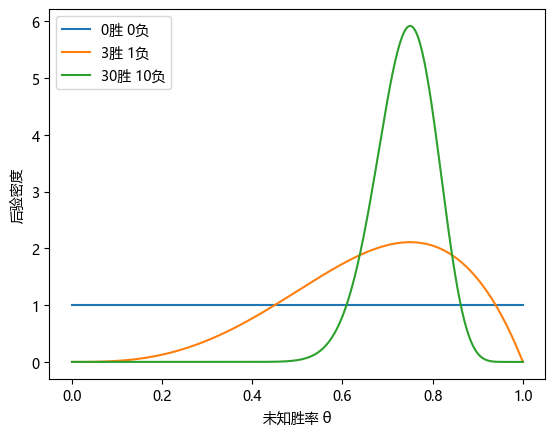

3 胜 1 负的后验均值 0.6666666666666666


In [10]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

q = np.linspace(0, 1, 400)
for wins, losses in [(0, 0), (3, 1), (30, 10)]:
    plt.plot(q, beta.pdf(q, 1 + wins, 1 + losses), label=f"{wins}胜 {losses}负")

plt.xlabel("未知胜率 θ")
plt.ylabel("后验密度")
plt.legend()
plt.show()

print("3 胜 1 负的后验均值", (1 + 3) / (2 + 4))



**读数与应用**：先验 $Beta(1,1)$ 是平的；3 胜 1 负后，后验向右移，但仍然很宽；30 胜 10 负后，后验明显变窄。**数据越多，估计越确定；但先验不会消失，只是权重变小。** 实盘里，如果你对某个策略的历史胜率没有把握，可以用一个弱先验，避免小样本把胜率推到 0 或 1。

**常见错误**：

1. 忽略基础发生率。看到“90% 准确”就以为报警很可信。
2. 把后验均值当成“真实胜率”。它仍是一个估计，只是把先验和 data 合在一起。
3. 先验选得太强，数据再多也拉不回来。先验应该是你愿意为之负责的假设。

**停下来想一想**：如果检测器的召回率提高到 99%，但误报率仍是 10%，报警的可靠性会变成多少？

<details><summary>对照你的思路</summary>

真阳性约 $10\times0.99=9.9$，假阳性仍是 99，所以 $9.9/(9.9+99)\approx9.1\%$。召回率提高一点，但基础发生率太低，后验仍然很小。这说明：**在稀有事件上，单靠提高召回率不够，必须降低误报率，或者提高事件的基础发生率（比如换一个更宽的趋势定义）。**

</details>

### 6.5 贝叶斯 A/B 测试

两个策略 A、B，各自跑出 $k_A,n_A$ 和 $k_B,n_B$。用 Beta 先验，后验分别是 $Beta(a+k_A,b+n_A-k_A)$ 和 $Beta(a+k_B,b+n_B-k_B)$。

想知道“B 比 A 好的概率”，可以从中各抽 10 万次，数一数 $P(\theta_B>\theta_A)$。这个数直接回答“哪个更好”，而不是“差异是否显著”。若这个概率只有 0.6，说明证据还很弱；若 0.95 以上，才值得考虑切换。

贝叶斯 A/B 测试的优点是解释直观；缺点是结果依赖先验，而且“抽 10 万次”只是数值近似。两种方法可以并用：频率学派告诉你“有没有证据”，贝叶斯告诉你“证据有多偏向哪一边”。

### 6.6 Beta 后验的推导

先验 $Beta(a,b)$ 的密度与 $\theta^{a-1}(1-\theta)^{b-1}$ 成正比；二项似然与 $\theta^k(1-\theta)^{n-k}$ 成正比。相乘：

$$\theta^{a-1}(1-\theta)^{b-1}\cdot\theta^k(1-\theta)^{n-k}=\theta^{a+k-1}(1-\theta)^{b+n-k-1}.$$

这正好是 $Beta(a+k,b+n-k)$ 的核，归一化常数由分母补上。所以后验还是 Beta，这叫“共轭先验”。

共轭的好处是算得快；坏处是模型受限。如果先验选得不对，后验会被拉偏，尤其在样本小的时候。

---



## 7. 马尔可夫链：把“趋势/震荡”写成矩阵

### 7.1 状态与转移

把市场简化为两个状态：趋势（T）、震荡（R）。若明天处于哪个状态，只依赖今天的状态，与更早的历史无关，称为**一阶马尔可夫性**：

$$P(S_{t+1}=j\mid S_t=i,S_{t-1},\dots)=P(S_{t+1}=j\mid S_t=i).$$

把条件概率排成矩阵：

$$P=\begin{pmatrix}p_{TT}&p_{TR}\\p_{RT}&p_{RR}\end{pmatrix},$$

每一行加起来等于 1。比如

$$P=\begin{pmatrix}0.8&0.2\\0.3&0.7\end{pmatrix}.$$

今天趋势，明天留趋势的概率 0.8；今天震荡，明天转趋势的概率 0.3。

### 7.2 两步、n 步与平稳分布

若今天是趋势，两步后仍是趋势的概率是

$$(P^2)_{TT}=0.8\times0.8+0.2\times0.3=0.70.$$

更一般地，$n$ 步转移矩阵是 $P^n$。

长期来看，状态分布会收敛到一个**平稳分布** $\pi=(\pi_T,\pi_R)$，满足

$$\pi P=\pi,\qquad \pi_T+\pi_R=1.$$

代入上面的矩阵：

$$\pi_T=0.8\pi_T+0.3\pi_R,\qquad \pi_R=0.2\pi_T+0.7\pi_R.$$

解得 $\pi_T=0.6,\pi_R=0.4$。也就是说，长期约 60% 的时间在趋势、40% 在震荡。这个数与初始状态无关（在满足一定条件的链里）。

### 7.3 从数据估计转移矩阵

数一数：从状态 $i$ 出发的所有日子里，有多少天转到了 $j$，再除以从 $i$ 出发的总天数：

$$\hat p_{ij}=\frac{N_{ij}}{\sum_j N_{ij}}.$$

小样本时，这个估计很不稳；某一行可能只有两三次观测，概率会被 0 或 1 主导。实务中要报每一行的样本数，必要时用先验做平滑。

### 7.4 代码：模拟与估计



In [11]:

import numpy as np

P = np.array([[0.8, 0.2], [0.3, 0.7]])
w = np.array([0.5, 0.5])

for step in range(1, 7):
    w = w @ P
    print(step, w.round(4))

vals, vecs = np.linalg.eig(P.T)
idx = np.argmin(np.abs(vals - 1))
pi = np.real(vecs[:, idx])
pi = pi / pi.sum()
print("平稳分布", pi.round(4))


1 [0.55 0.45]
2 [0.575 0.425]
3 [0.5875 0.4125]
4 [0.5938 0.4062]
5 [0.5969 0.4031]
6 [0.5984 0.4016]
平稳分布 [0.6 0.4]



**读数与应用**：从 [0.5, 0.5] 出发，几步后就接近 [0.6, 0.4]。`P.T` 的特征值 1 对应的特征向量就是平稳分布；`np.real` 是为了去掉数值计算产生的极小虚部。实盘里，转移矩阵可以从“按状态分组的次日状态频数”估计，但状态标签必须用当时可见的信息，不能事后回看。

**常见错误**：

1. 用未来信息定义状态。比如用“事后知道这段是趋势”来标注每天的状态，再估计转移矩阵，实盘无法复现。
2. 用全样本估计转移矩阵，再回测同一段。这会把未来状态转移的信息泄露到过去。
3. 样本太少就相信平稳分布。两三行观测估出来的矩阵，平稳分布可能完全不可信。

**停下来想一想**：如果只用 5 天的数据估计转移矩阵，会有什么问题？

<details><summary>对照你的思路</summary>

每一行最多只有几次观测，很多转移次数是 0；估出来的概率会是 0、0.5、1 这类粗糙值，平稳分布也会被极端值主导。更合理的做法是：扩大样本、合并状态、加先验平滑，或者只把转移矩阵当作定性工具，不拿它做精确预测。

</details>

### 7.5 状态定义与回测

状态标签必须是“当时可见”的。比如用“过去 20 天的收益均值 > 0”定义趋势，这个标签在每天收盘后就能算；若用“事后知道这段是趋势”来标注，回测就会偷看未来。

做法：

1. 在训练段确定阈值（比如过去 20 天收益的 60% 分位）；
2. 把阈值原样搬到测试段，不重新拟合；
3. 用训练段估计转移矩阵，测试段只做应用；
4. 报告测试段每一行的样本数，样本太少的行不要解释。

状态模型的价值在于“把定性判断变成可复现的规则”，不是“预测明天一定是什么状态”。

### 7.6 马尔可夫链的局限

一阶马尔可夫假设说“明天只依赖今天”。真实市场可能依赖更长历史：连续三天缩量、连续两根大阴线，都会改变第二天的分布。若忽略这些，转移矩阵会把不同历史压成同一个概率。

三个检查：

1. **状态定义是否可复现**：换一个人按同样规则标注，能否得到同一串状态？
2. **转移是否稳定**：训练段和测试段的转移矩阵是否接近？
3. **高阶是否有用**：加入 $S_{t-1}$ 后，预测是否明显改善？如果改善很小，一阶够用。

马尔可夫链是“把状态切换写成矩阵”的起点，不是终点。

---



## 8. 统计在因子研究中的位置

### 8.1 IC、t 值、ICIR

因子研究里，最常用的三个数：

- **IC**：每个截面日，因子值与未来收益的相关系数（常用 Rank IC）。它衡量“排序对不对”；
- **t 值**：IC 均值除以它的标准误，衡量“这个平均 IC 有多稳”；
- **ICIR**：IC 均值除以 IC 标准差，衡量“单位波动带来多少预测力”。

若每天算一个 IC，共 $T$ 天：

$$\bar{IC}=\frac{1}{T}\sum_{t=1}^T IC_t,\qquad SE(\bar{IC})=\frac{s_{IC}}{\sqrt T},\qquad t=\frac{\bar{IC}}{SE}.$$

$t$ 值大约 2 以上，才在 5% 水平上“显著”（大样本、独立、正态的近似）。但 IC 序列常有自相关，普通标准误会低估，t 值会虚高；这时要用 Newey-West 调整，或用块状 bootstrap。

### 8.2 一个因子报告的最小清单

| 检查项 | 要回答的问题 |
|---|---|
| 覆盖率 | 每天有多少标的能算出因子？缺失集中在哪里？ |
| IC 均值与 t 值 | 排序能力是否稳定？ |
| IC 的时序 | 是少数几天撑起来的，还是长期为正？ |
| 分组单调性 | 高分组是否真的比低分组好？ |
| 换手与费用 | 扣费后还剩多少？ |
| 样本外 | 有没有在未参与选择的数据上验证？ |
| 多重检验 | 试了多少个因子？怎么校正？ |

**一个高 IC 的因子，不一定能赚钱。** IC 只说明排序有一点预测力；能不能覆盖成本，要看价差、滑点、容量和换手。第16、18章会用真实数据走一遍。

### 8.3 代码：IC 的 t 值与 bootstrap



In [12]:

import numpy as np

rng = np.random.default_rng(21)
days = 60
raw = rng.normal(0, 1, size=days)
ic = 0.03 + (raw - raw.mean()) * 0.08 / raw.std(ddof=1)   # 教学用合成 IC，均值 0.03、标准差 0.08

t_stat = ic.mean() / (ic.std(ddof=1) / np.sqrt(days))
boot = rng.choice(ic, size=(10_000, days), replace=True).mean(axis=1)

print("平均 IC、IC 标准差、t 值", round(ic.mean(), 4), round(ic.std(ddof=1), 4), round(t_stat, 3))
print("95% bootstrap 区间", tuple(round(float(v), 4) for v in np.quantile(boot, [.025, .975])))


平均 IC、IC 标准差、t 值 0.03 0.08 2.905
95% bootstrap 区间 (0.01, 0.0502)



**读数与应用**：平均 IC 0.03、标准差 0.08、60 天，t 值约 2.9，看起来显著；但这是合成的独立 IC。真实 IC 若有自相关，有效样本会小于 60，t 值要打折。bootstrap 区间给出另一种不确定性度量，和 t 检验互为对照。

**常见错误**：

1. 把所有股票、所有日期混在一起算一个 IC。这会把“日间涨跌”混进“截面排序”，得到虚高的相关。
2. 用重叠的未来收益（比如 5 日标签每天滚动）却不调整标准误。相邻 IC 高度相关，t 值会被放大。
3. 试了 50 个因子，只报最显著的那个。这是多重检验，不是发现。

**停下来想一想**：IC 的 t 值很大，是否意味着因子一定赚钱？

<details><summary>对照你的思路</summary>

不一定。t 值大只说明“平均 IC 不容易是零”，不代表 IC 足够大、换手足够低、成本足够小。一个 IC=0.02、t=4 的因子，扣掉双边价差和手续费后可能净亏；一个 IC=0.05、t=2 的因子，如果容量大、换手低，反而可能赚钱。**统计显著是入场券，不是盈利保证。**

</details>

### 8.4 从 IC 到组合：还差哪几步

IC 只是“排序有没有用”，离“账户赚不赚钱”还有五步：

| 步骤 | 要回答的问题 | 常见错误 |
|---|---|---|
| 1. 打分 | 因子值怎么变成可比较的分数？ | 不标准化、不中性化 |
| 2. 组合 | 高分买多少、低分卖多少？ | 等权 all-in，忽略风险 |
| 3. 约束 | 行业、品种、杠杆、保证金 | 约束只在回测最后加 |
| 4. 成本 | 价差、手续费、冲击成本 | 只算手续费，不算滑点 |
| 5. 容量 | 这个策略能装多少钱？ | 用无限流动性回测 |

一个常见的误区是“IC 高就重仓”。IC 高只说明排序有一点预测力；如果换手很高，成本会吃掉全部收益；如果容量很小，资金一大就失效。**IC 是原料，组合是菜；原料好不等于菜好吃。**

第 9 章会讲组合优化，第16、18章会用真实数据把这条链路走一遍。

---



## 本章小结

### 一张公式表

| 概念 | 公式 | 用途 |
|---|---|---|
| 条件概率 | $P(A\mid B)=P(A\cap B)/P(B)$ | 看到信号后，结果的条件分布 |
| 期望 | $E[X]=\sum xp(x)$ | 长期平均盈亏 |
| 方差 | $\operatorname{Var}(X)=E[X^2]-(E[X])^2$ | 单笔风险 |
| 协方差 | $\operatorname{Cov}(X,Y)=E[XY]-E[X]E[Y]$ | 两个策略是否同向 |
| 组合方差 | $w^2\sigma_X^2+(1-w)^2\sigma_Y^2+2w(1-w)\rho\sigma_X\sigma_Y$ | 分散化 |
| 标准误 | $s/\sqrt n$ | 均值估计的稳定性 |
| t 统计量 | $(\bar x-\mu_0)/(s/\sqrt n)$ | 均值检验 |
| 贝叶斯 | $P(\theta\mid D)\propto P(D\mid\theta)P(\theta)$ | 更新信念 |
| Beta 后验 | $Beta(a+k,b+n-k)$ | 胜率的不确定性 |
| 平稳分布 | $\pi P=\pi$ | 长期状态占比 |

### 八句话

1. 概率是模型，不是保证；样本里的 60% 不等于未来的 60%。
2. 期望看长期，方差看波动；费用会改变期望，不改变方差。
3. 相关性是分散化的原材料，但极端行情下相关性会变。
4. 正态是基准，不是真理；真实收益的尾部更厚。
5. 标准误衡量“估计有多稳”，不衡量“下一笔有多安全”。
6. p 值不是“$H_0$ 为真的概率”，也不是“策略赚钱的概率”。
7. 贝叶斯更新的是信念，基础发生率决定后验的量级。
8. 高 IC 只是入场券；扣费、容量、样本外，才是能不能赚钱的答案。

---

## 本章习题

> 先自己算，再展开答案。每题都要写清“分母是谁、单位是什么”。

**1.** 100 个交易日，55 天上涨、45 天下跌。求 $P(\text{涨})$ 和上涨的赔率（odds）。

**2.** 两个信号 $A,B$ 独立，$P(A)=0.3$，$P(B)=0.4$。求 $P(A\cup B)$、$P(A\cap B)$、$P(A\mid B)$。

**3.** 一笔交易 60% 赚 3 元、40% 亏 1 元。求期望、方差、标准差。

**4.** 两个策略 $\operatorname{Var}(X)=4$、$\operatorname{Var}(Y)=9$，相关系数 0.5，权重各 0.5。求组合方差与组合标准差。

**5.** $X\sim N(0,2^2)$。用 68-95 法则求 $P(X>2)$ 和 $P(|X|<4)$。

**6.** 一分钟订单数服从 $Poisson(3)$。求零单概率、至少一单概率。

**7.** 25 笔交易，均值 1.2，样本标准差 3。求标准误和 95% 置信区间（$t_{0.975,24}=2.064$）。

**8.** 60 天的日 IC 均值 0.03、标准差 0.08。求 t 值；在 5% 水平下是否显著？如果这是 20 个因子中最好的一个，结论要怎么改？

<details><summary>参考答案</summary>

**1.** $P(\text{涨})=0.55$；odds $=0.55/0.45\approx1.22$。

**2.** $P(A\cap B)=0.12$；$P(A\cup B)=0.3+0.4-0.12=0.58$；$P(A\mid B)=P(A)=0.3$（独立）。

**3.** $E=0.6\times3+0.4\times(-1)=1.4$；$\operatorname{Var}=0.6(3-1.4)^2+0.4(-1-1.4)^2=0.6\times2.56+0.4\times5.76=3.84$；$\operatorname{SD}\approx1.96$。

**4.** $\operatorname{Cov}=0.5\times2\times3=3$；$\operatorname{Var}=0.25\times4+0.25\times9+2\times0.25\times3=1+2.25+1.5=4.75$；$\operatorname{SD}\approx2.18$。

**5.** $P(X>2)=P(Z>1)\approx0.1587$；$P(|X|<4)=P(|Z|<2)\approx0.9545$。

**6.** $P(0)=e^{-3}\approx0.0498$；$P(\ge1)=1-0.0498=0.9502$。

**7.** $SE=3/\sqrt{25}=0.6$；区间 $1.2\pm2.064\times0.6=1.2\pm1.238=[-0.038,\ 2.438]$。

**8.** $t=0.03/(0.08/\sqrt{60})\approx2.90$，大于 2，单看这个因子在 5% 水平下显著。但它是 20 个因子中最好的一个，存在多重检验：即使全是噪声，也约 64% 的概率出现至少一个“显著”。应做 Bonferroni/FDR 校正，并在未参与选择的样本外验证。

</details>

---

## 参考资料

- Casella, G. & Berger, R. L. *Statistical Inference*（概率与统计推断的标准教材）。
- Ross, S. *Introduction to Probability Models*（泊松过程、马尔可夫链）。
- Hyndman, R. J. & Athanasopoulos, G. *Forecasting: Principles and Practice*（第 3 版，在线：https://otexts.com/fpp3/）。
- Harvard Stat 110（概率入门课程：https://stat110.hsites.harvard.edu/）。
- Harvey, C. R., Liu, Y., & Zhu, H. *… and the Cross-Section of Expected Returns*（多重检验与因子发现）。
